# Importation des bibliothèques nécessaires

In [7]:
# Import des bibliothèques nécessaires
import numpy as np
import scipy.linalg as la
import matplotlib.pyplot as plt
import time
from matplotlib import cm
from matplotlib.ticker import LinearLocator
import seaborn as sns
sns.set_style("whitegrid")
np.random.seed(42)  # Pour la reproductibilité des résultats

# Exercice 1 : Résolution de Systèmes Linéaires

In [8]:
print("EXERCICE 1 : RÉSOLUTION DE SYSTÈMES LINÉAIRES")

# 1.1 Méthodes Directes : Décomposition LU
print("\n1.1 Méthodes Directes : Décomposition LU")

# Création d'une matrice A (4x4) symétrique définie positive
B = np.random.rand(4, 4)
A = np.dot(B.T, B) + 0.1 * np.eye(4)
print("Matrice A (symétrique définie positive) :")
print(A)

# Création d'un vecteur b (4x1) aléatoire
b = np.random.rand(4)
print("\nVecteur b :")
print(b)

# Décomposition LU
P, L, U = la.lu(A)
print("\nMatrice P :")
print(P)
print("\nMatrice L :")
print(L)
print("\nMatrice U :")
print(U)
print("\nVérification P*A = L*U:")
print(np.allclose(np.dot(P, A), np.dot(L, U)))

# Résolution triangulaire
y = la.solve_triangular(L, np.dot(P, b), lower=True)
print("\nVecteur y (solution de Ly = Pb) :")
print(y)
x_lu = la.solve_triangular(U, y, lower=False)
print("\nVecteur x (solution de Ux = y) :")
print(x_lu)

# Vérification avec np.linalg.solve
x_np = np.linalg.solve(A, b)
print("\nSolution avec numpy.linalg.solve :")
print(x_np)
print("\nLes solutions sont-elles équivalentes ?", np.allclose(x_lu, x_np))
residual_lu = np.linalg.norm(np.dot(A, x_lu) - b)
print(f"\nErreur résiduelle pour la méthode LU : {residual_lu:.2e}")

# 1.2 Méthode de Cholesky
print("\n1.2 Méthode de Cholesky")

# Temps pour LU
start_time = time.time()
P, L, U = la.lu(A)
y = la.solve_triangular(L, np.dot(P, b), lower=True)
x_lu = la.solve_triangular(U, y, lower=False)
time_lu = time.time() - start_time
print(f"Temps d'exécution pour la méthode LU : {time_lu:.6f} secondes")

# Temps pour Cholesky
start_time = time.time()
c_factor = la.cho_factor(A)
x_chol = la.cho_solve(c_factor, b)
time_chol = time.time() - start_time

print("\nSolution avec la méthode de Cholesky :")
print(x_chol)
print("\nLes solutions LU et Cholesky sont-elles équivalentes ?", np.allclose(x_lu, x_chol))
residual_chol = np.linalg.norm(np.dot(A, x_chol) - b)
print(f"Erreur résiduelle pour la méthode de Cholesky : {residual_chol:.2e}")
print(f"Temps d'exécution pour la méthode de Cholesky : {time_chol:.6f} secondes")

# Comparaison sécurisée
print("\nComparaison des méthodes :")
if time_chol != 0:
    print(f"Ratio de temps (LU/Cholesky) : {time_lu / time_chol:.2f}")
else:
    print("Le temps d'exécution pour Cholesky est nul, ratio de temps non calculable.")

if residual_chol != 0:
    print(f"Ratio d'erreur (LU/Cholesky) : {residual_lu / residual_chol:.2f}")
else:
    print("L'erreur résiduelle pour Cholesky est nulle, ratio d'erreur non calculable.")

# 1.3 Méthodes Itératives : Jacobi et Gauss-Seidel
print("\n1.3 Méthodes Itératives : Jacobi et Gauss-Seidel")

def jacobi_method(A, b, tol=1e-6, max_iter=100):
    n = len(b)
    x = np.zeros_like(b)
    x_new = np.zeros_like(b)
    iter_count = 0
    D = np.diag(np.diag(A))
    L = np.tril(A, -1)
    U = np.triu(A, 1)
    D_inv = np.diag(1.0 / np.diag(A))
    while iter_count < max_iter:
        x_new = np.dot(D_inv, b - np.dot(L + U, x))
        if np.linalg.norm(x_new - x) < tol:
            break
        x = x_new.copy()
        iter_count += 1
    residual = np.linalg.norm(np.dot(A, x) - b)
    return x, iter_count, residual

def gauss_seidel_method(A, b, tol=1e-6, max_iter=100):
    n = len(b)
    x = np.zeros_like(b)
    iter_count = 0
    for _ in range(max_iter):
        x_old = x.copy()
        for i in range(n):
            s1 = sum(A[i, j] * x[j] for j in range(i))
            s2 = sum(A[i, j] * x_old[j] for j in range(i + 1, n))
            x[i] = (b[i] - s1 - s2) / A[i, i]
        if np.linalg.norm(x - x_old) < tol:
            break
        iter_count += 1
    residual = np.linalg.norm(np.dot(A, x) - b)
    return x, iter_count, residual

# Exécution
tolerance = 1e-6
max_iterations = 100

start_time = time.time()
x_jacobi, iter_jacobi, res_jacobi = jacobi_method(A, b, tolerance, max_iterations)
time_jacobi = time.time() - start_time
print("Résultats de la méthode de Jacobi:")
print(f"Solution: {x_jacobi}")
print(f"Nombre d'itérations: {iter_jacobi}")
print(f"Erreur résiduelle: {res_jacobi:.2e}")
print(f"Temps d'exécution: {time_jacobi:.6f} secondes")

start_time = time.time()
x_gauss, iter_gauss, res_gauss = gauss_seidel_method(A, b, tolerance, max_iterations)
time_gauss = time.time() - start_time
print("\nRésultats de la méthode de Gauss-Seidel:")
print(f"Solution: {x_gauss}")
print(f"Nombre d'itérations: {iter_gauss}")
print(f"Erreur résiduelle: {res_gauss:.2e}")
print(f"Temps d'exécution: {time_gauss:.6f} secondes")

print("\nComparaison avec la solution exacte (numpy.linalg.solve):")
print(f"Erreur relative Jacobi: {np.linalg.norm(x_jacobi - x_np) / np.linalg.norm(x_np):.2e}")
print(f"Erreur relative Gauss-Seidel: {np.linalg.norm(x_gauss - x_np) / np.linalg.norm(x_np):.2e}")

# Résumé comparatif
methods = ["LU", "Cholesky", "Jacobi", "Gauss-Seidel"]
times = [time_lu, time_chol, time_jacobi, time_gauss]
iters = ["N/A", "N/A", iter_jacobi, iter_gauss]
errs = [residual_lu, residual_chol, res_jacobi, res_gauss]

print("\nTableau comparatif des méthodes:")
print(f"{'Méthode':<12} | {'Temps (s)':<10} | {'Itérations':<10} | {'Erreur':<10}")
print("-" * 50)
for i in range(len(methods)):
    print(f"{methods[i]:<12} | {times[i]:<10.6f} | {iters[i]:<10} | {errs[i]:<10.2e}")


EXERCICE 1 : RÉSOLUTION DE SYSTÈMES LINÉAIRES

1.1 Méthodes Directes : Décomposition LU
Matrice A (symétrique définie positive) :
[[1.31892212 0.98281189 0.44695573 1.09506235]
 [0.98281189 1.57464666 0.75816171 1.42998244]
 [0.44695573 0.75816171 0.67267288 0.54183765]
 [1.09506235 1.42998244 0.54183765 2.18301543]]

Vecteur b :
[0.30424224 0.52475643 0.43194502 0.29122914]

Matrice P :
[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]

Matrice L :
[[ 1.          0.          0.          0.        ]
 [ 0.74516294  1.          0.          0.        ]
 [ 0.33887954  0.50470268  1.          0.        ]
 [ 0.83027067  0.72894294 -0.45371739  1.        ]]

Matrice U :
[[ 1.31892212  0.98281189  0.44695573  1.09506235]
 [ 0.          0.84229166  0.42510686  0.61398256]
 [ 0.          0.          0.30665615 -0.13913523]
 [ 0.          0.          0.          0.76313096]]

Vérification P*A = L*U:
True

Vecteur y (solution de Ly = Pb) :
[ 0.30424224  0.29804639  0.17841873 -0.0976814

# Exercice 2 : Décompositions SVD et QR



EXERCICE 2 : DÉCOMPOSITIONS SVD ET QR

2.1 Décomposition SVD
Matrice de données D (10x5) :
[[0.61185289 0.13949386 0.29214465 0.36636184 0.45606998]
 [0.78517596 0.19967378 0.51423444 0.59241457 0.04645041]
 [0.60754485 0.17052412 0.06505159 0.94888554 0.96563203]
 [0.80839735 0.30461377 0.09767211 0.68423303 0.44015249]
 [0.12203823 0.49517691 0.03438852 0.9093204  0.25877998]
 [0.66252228 0.31171108 0.52006802 0.54671028 0.18485446]
 [0.96958463 0.77513282 0.93949894 0.89482735 0.59789998]
 [0.92187424 0.0884925  0.19598286 0.04522729 0.32533033]
 [0.38867729 0.27134903 0.82873751 0.35675333 0.28093451]
 [0.54269608 0.14092422 0.80219698 0.07455064 0.98688694]]

Matrice U :
[[-0.24851035  0.05138401 -0.15466022  0.13671853  0.0782981 ]
 [-0.28973767  0.01878484  0.35697     0.31179572  0.55506554]
 [-0.36629481 -0.40120959 -0.57555708 -0.08512899  0.3715197 ]
 [-0.31386492 -0.24529142 -0.11176413  0.334495   -0.16112058]
 [-0.22022007 -0.58235732  0.13769566 -0.30986784 -0.23163783

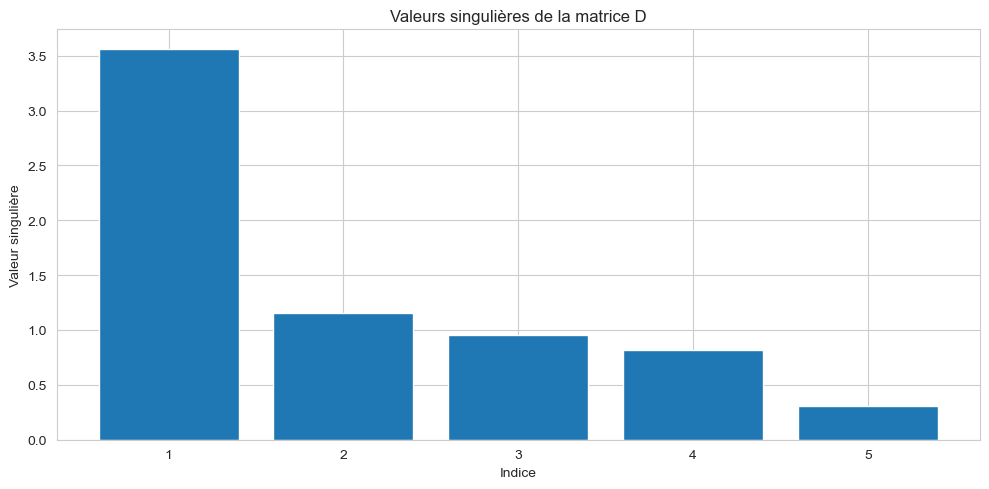


2.2 Décomposition QR
Matrice Q (orthogonale) :
[[-0.28214126 -0.15073691 -0.02232993  0.07237252  0.07126242 -0.31635468
  -0.51146689 -0.14355886 -0.44842128 -0.55089972]
 [-0.36206502 -0.16357745  0.10333744  0.30279023 -0.5973554  -0.34233889
   0.24488267 -0.04801898 -0.25117099  0.37470145]
 [-0.28015471 -0.10341903 -0.27684219  0.68247424  0.37428061  0.12041587
   0.34632457  0.19192236  0.11211937 -0.21088753]
 [-0.37277301 -0.02531451 -0.40609874 -0.06026887  0.02946154  0.02147564
  -0.21476605 -0.64004051  0.43769611  0.20776805]
 [-0.056275    0.64524002 -0.32585098  0.15297855  0.08478396 -0.18006662
  -0.37305593  0.34961173 -0.13313788  0.36356574]
 [-0.30550623  0.06893431  0.08605174  0.06234136 -0.29361998  0.83919043
  -0.23493614  0.06650336 -0.20093924 -0.01323345]
 [-0.44710065  0.56175435  0.10934911 -0.36037822  0.05397994 -0.05605612
   0.48478498 -0.11376659 -0.09127132 -0.28347395]
 [-0.42510015 -0.40293905 -0.21074475 -0.48144949  0.04422007 -0.06747679
  -

In [9]:
print("\n\nEXERCICE 2 : DÉCOMPOSITIONS SVD ET QR")

# 2.1 Décomposition SVD
print("\n2.1 Décomposition SVD")

# Création d'une matrice de données D (10x5)
D = np.random.rand(10, 5)
print("Matrice de données D (10x5) :")
print(D)

# Utilisation de numpy.linalg.svd pour obtenir U, S, V
U, S, Vt = np.linalg.svd(D, full_matrices=False)
print("\nMatrice U :")
print(U)
print("\nValeurs singulières S :")
print(S)
print("\nMatrice V transposée :")
print(Vt)

# Reconstruction de la matrice à partir de U, S, V
S_matrix = np.diag(S)
D_reconstructed = np.dot(U, np.dot(S_matrix, Vt))
print("\nMatrice reconstruite à partir de U, S, V :")
print(D_reconstructed)

# Vérification de l'exactitude
reconstruction_error = np.linalg.norm(D - D_reconstructed)
print(f"\nErreur de reconstruction : {reconstruction_error:.2e}")

# Réduction de la dimension en gardant que les 2 premières valeurs singulières
k = 2
S_reduced = np.diag(S[:k])
D_approximated = np.dot(U[:, :k], np.dot(S_reduced, Vt[:k, :]))
print("\nMatrice approximée (2 premières valeurs singulières) :")
print(D_approximated)

# Calcul de l'erreur d'approximation
approximation_error = np.linalg.norm(D - D_approximated)
print(f"\nErreur d'approximation (k=2) : {approximation_error:.2e}")
print(f"Pourcentage d'information conservée : {sum(S[:k]**2) / sum(S**2) * 100:.2f}%")

# Plot des valeurs singulières
plt.figure(figsize=(10, 5))
plt.bar(range(1, len(S) + 1), S)
plt.xlabel('Indice')
plt.ylabel('Valeur singulière')
plt.title('Valeurs singulières de la matrice D')
plt.grid(True)
plt.tight_layout()
plt.show()

# 2.2 Décomposition QR
print("\n2.2 Décomposition QR")

# Utilisation de scipy.linalg.qr pour décomposer la matrice D en Q et R
Q, R = la.qr(D)
print("Matrice Q (orthogonale) :")
print(Q)
print("\nMatrice R (triangulaire supérieure) :")
print(R)

# Vérification que Q est orthogonale (Q^T Q = I)
Q_orthogonality = np.dot(Q.T, Q)
print("\nVérification Q^T Q (devrait être proche de I) :")
print(Q_orthogonality)
print(f"Écart à l'identité : {np.linalg.norm(Q_orthogonality - np.eye(Q.shape[1])):.2e}")

# Vérification que QR = D
D_reconstructed_qr = np.dot(Q, R)
print("\nVérification QR = D :")
print(f"Erreur de reconstruction : {np.linalg.norm(D - D_reconstructed_qr):.2e}")

# Exercice 3 : Application à l'Analyse de Données



EXERCICE 3 : APPLICATION À L'ANALYSE DE DONNÉES

3.1 Analyse en Composantes Principales (ACP)
Matrice de données originale :
[[0.61185289 0.13949386 0.29214465 0.36636184 0.45606998]
 [0.78517596 0.19967378 0.51423444 0.59241457 0.04645041]
 [0.60754485 0.17052412 0.06505159 0.94888554 0.96563203]
 [0.80839735 0.30461377 0.09767211 0.68423303 0.44015249]
 [0.12203823 0.49517691 0.03438852 0.9093204  0.25877998]
 [0.66252228 0.31171108 0.52006802 0.54671028 0.18485446]
 [0.96958463 0.77513282 0.93949894 0.89482735 0.59789998]
 [0.92187424 0.0884925  0.19598286 0.04522729 0.32533033]
 [0.38867729 0.27134903 0.82873751 0.35675333 0.28093451]
 [0.54269608 0.14092422 0.80219698 0.07455064 0.98688694]]

Matrice centrée :
[[-0.03018349 -0.15021535 -0.13685291 -0.17556658  0.00177087]
 [ 0.14313958 -0.09003543  0.08523688  0.05048614 -0.4078487 ]
 [-0.03449153 -0.11918509 -0.36394597  0.40695711  0.51133292]
 [ 0.16636097  0.01490456 -0.33132545  0.1423046  -0.01414662]
 [-0.51999815  0.2054

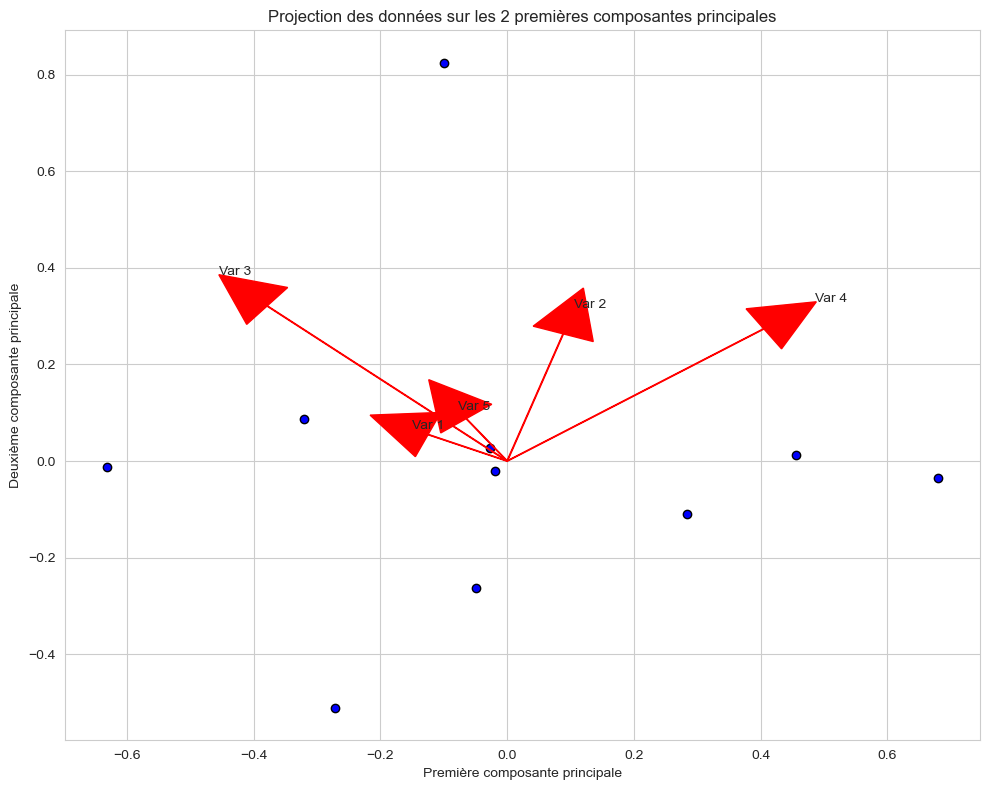


Pourcentage de variance expliquée par chaque composante :
Composante 1: 34.53%
Composante 2: 26.59%
Composante 3: 22.82%
Composante 4: 13.86%
Composante 5: 2.21%


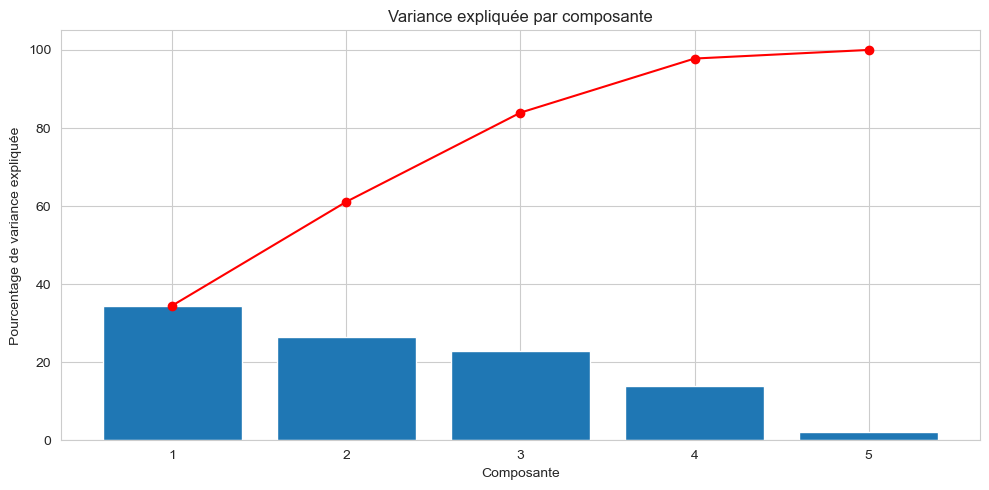


3.2 Compression d'Image
Image chargée avec succès !
Dimensions de l'image : (256, 256)
Type de données : float64
Valeurs min/max : 16.55 / 239.43

Application de la SVD sur l'image...
Nombre de valeurs singulières : 256

Compression avec différents nombres de valeurs singulières :
Total de valeurs singulières disponibles : 256

--- Compression avec 12 valeurs singulières ---
Erreur relative: 0.0878
Taux de compression: 0.0939 (10.6:1)
Énergie conservée: 99.23%
Économie d'espace: 90.6%

--- Compression avec 25 valeurs singulières ---
Erreur relative: 0.0496
Taux de compression: 0.1957 (5.1:1)
Énergie conservée: 99.75%
Économie d'espace: 80.4%

--- Compression avec 64 valeurs singulières ---
Erreur relative: 0.0180
Taux de compression: 0.5010 (2.0:1)
Énergie conservée: 99.97%
Économie d'espace: 49.9%

--- Compression avec 128 valeurs singulières ---
Erreur relative: 0.0057
Taux de compression: 1.0020 (1.0:1)
Énergie conservée: 100.00%
Économie d'espace: -0.2%

--- Compression avec 256 v

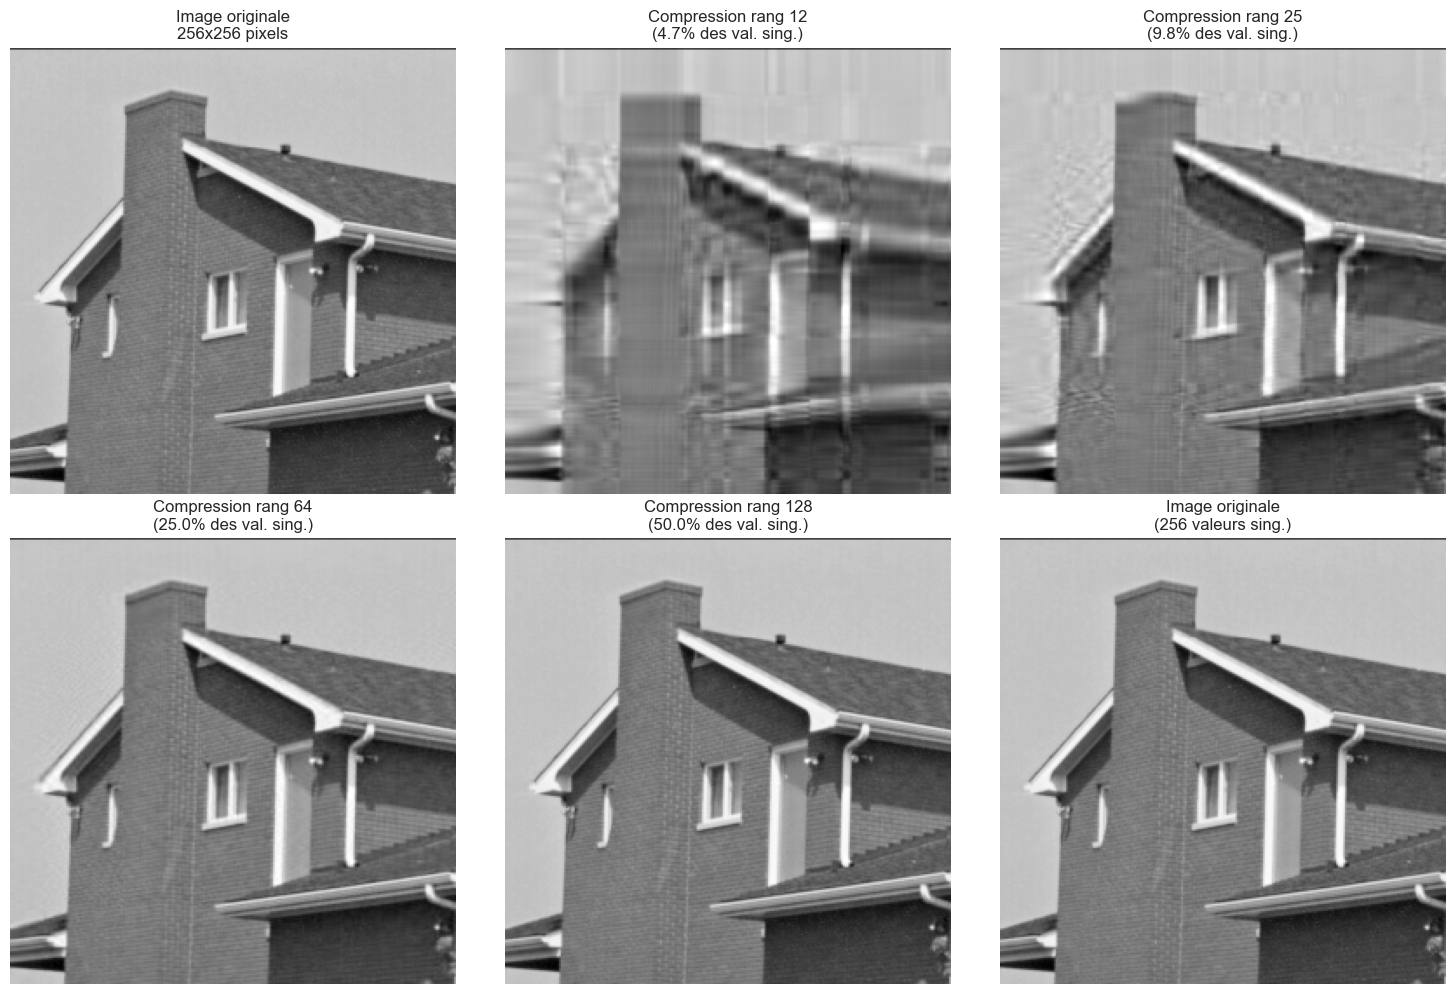

C:\Users\PC\AppData\Local\Temp\ipykernel_16936\4024630726.py:277: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\PC\AppData\Local\Temp\ipykernel_16936\4024630726.py:277: UserWarning: Glyph 8320 (\N{SUBSCRIPT ZERO}) missing from font(s) Arial.
  plt.tight_layout()


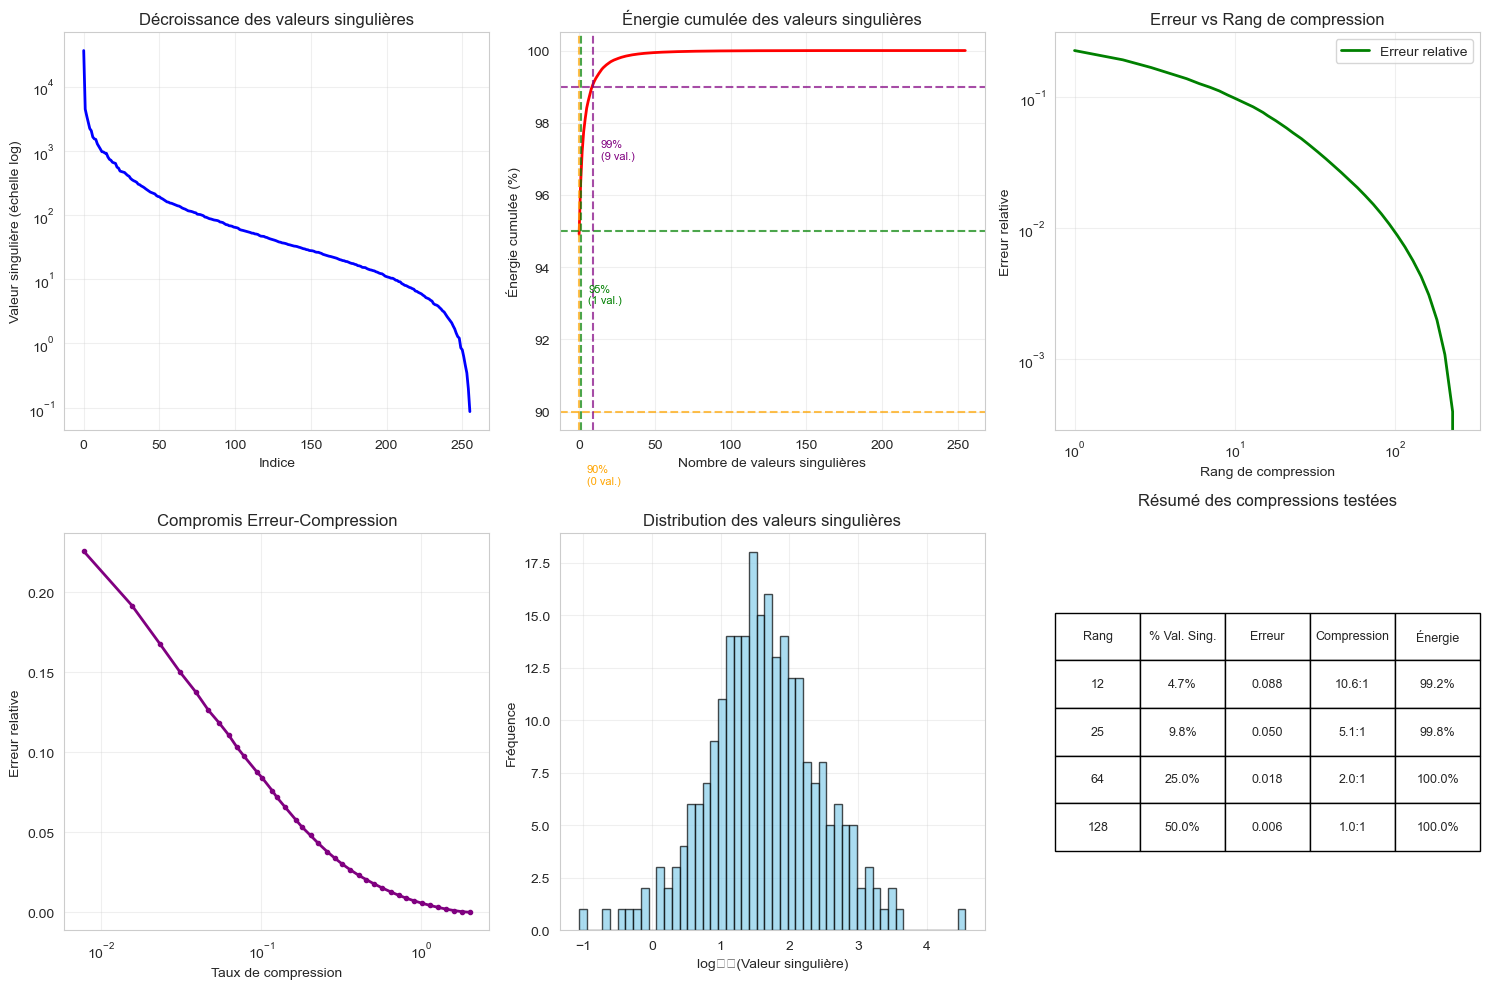


ANALYSE DE LA COMPRESSION D'IMAGE PAR SVD
Dimensions de l'image : 256 × 256 = 65,536 pixels
Nombre total de valeurs singulières disponibles : 256

Rangs nécessaires pour différents niveaux de qualité :
   90.0% d'énergie → Rang    1 → Compression 127.8:1
   95.0% d'énergie → Rang    2 → Compression 63.9:1
   99.0% d'énergie → Rang   10 → Compression 12.8:1
   99.9% d'énergie → Rang   40 → Compression 3.2:1

La SVD permet une compression efficace en concentrant l'information dans les premières valeurs singulières.
Pour cette image, on peut obtenir une qualité visuelle acceptable avec seulement
2 valeurs singulières sur 256 disponibles.


In [10]:
print("\n\nEXERCICE 3 : APPLICATION À L'ANALYSE DE DONNÉES")

# 3.1 Analyse en Composantes Principales (ACP)
print("\n3.1 Analyse en Composantes Principales (ACP)")

# Utilisation de la même matrice de données D
print("Matrice de données originale :")
print(D)

# Centrage des données (soustraction de la moyenne de chaque colonne)
D_centered = D - np.mean(D, axis=0)
print("\nMatrice centrée :")
print(D_centered)

# Application de la SVD sur la matrice centrée
U_centered, S_centered, Vt_centered = np.linalg.svd(D_centered, full_matrices=False)

# Projection des données sur les deux premières composantes principales
composantes_principales = Vt_centered[:2, :]
print("\nComposantes principales (2 premières lignes de V^T) :")
print(composantes_principales)

# Projection des données
donnees_projetees = np.dot(D_centered, composantes_principales.T)
print("\nDonnées projetées sur les deux premières composantes :")
print(donnees_projetees)

# Visualisation des données projetées
plt.figure(figsize=(10, 8))
plt.scatter(donnees_projetees[:, 0], donnees_projetees[:, 1], c='blue', edgecolors='k')
plt.xlabel('Première composante principale')
plt.ylabel('Deuxième composante principale')
plt.title('Projection des données sur les 2 premières composantes principales')
plt.grid(True)

# Ajout des vecteurs propres
for i in range(composantes_principales.shape[1]):
    plt.arrow(0, 0, 
              composantes_principales[0, i] * S_centered[0] * 0.5, 
              composantes_principales[1, i] * S_centered[1] * 0.5,
              head_width=0.1, head_length=0.1, fc='red', ec='red')
    plt.text(composantes_principales[0, i] * S_centered[0] * 0.6, 
             composantes_principales[1, i] * S_centered[1] * 0.6, 
             f'Var {i+1}')

plt.tight_layout()
plt.show()

# Pourcentage de variance expliquée par chaque composante
explained_variance = (S_centered ** 2) / (sum(S_centered ** 2)) * 100
print("\nPourcentage de variance expliquée par chaque composante :")
for i, variance in enumerate(explained_variance):
    print(f"Composante {i+1}: {variance:.2f}%")

# Visualisation de la variance expliquée cumulée
plt.figure(figsize=(10, 5))
plt.bar(range(1, len(explained_variance) + 1), explained_variance)
plt.plot(range(1, len(explained_variance) + 1), np.cumsum(explained_variance), 'r-o')
plt.xlabel('Composante')
plt.ylabel('Pourcentage de variance expliquée')
plt.title('Variance expliquée par composante')
plt.grid(True)
plt.tight_layout()
plt.show()

# 3.2 Compression d'Image
print("\n3.2 Compression d'Image")

# Import nécessaire pour le traitement d'images
import matplotlib.image as mpimg
from PIL import Image

# Chargement d'une image en niveaux de gris avec matplotlib.image
chemin_image = "house.tiff"  

try:
    # Chargement de l'image
    if chemin_image.lower().endswith(('.png', '.jpg', '.jpeg')):
        # Utilisation de PIL pour une meilleure compatibilité
        img_pil = Image.open(chemin_image)
        # Conversion en niveaux de gris si nécessaire
        if img_pil.mode != 'L':
            img_pil = img_pil.convert('L')
        Z = np.array(img_pil)
    else:
        # Utilisation de matplotlib pour d'autres formats
        img = mpimg.imread(chemin_image)
        # Si l'image est en couleur (3 dimensions), conversion en niveaux de gris
        if len(img.shape) == 3:
            # Conversion RGB en niveaux de gris : 0.299*R + 0.587*G + 0.114*B
            Z = np.dot(img[...,:3], [0.299, 0.587, 0.114])
        else:
            Z = img
    
    print(f"Image chargée avec succès !")
    print(f"Dimensions de l'image : {Z.shape}")
    print(f"Type de données : {Z.dtype}")
    print(f"Valeurs min/max : {Z.min():.2f} / {Z.max():.2f}")
    
except FileNotFoundError:
    print(f"ATTENTION: Image non trouvée au chemin '{chemin_image}'")
    print("Création d'une image synthétique pour la démonstration...")
    
    # Image synthétique de secours
    image_size = 200
    x = np.linspace(-5, 5, image_size)
    y = np.linspace(-5, 5, image_size)
    X, Y = np.meshgrid(x, y)
    Z = np.sin(np.sqrt(X**2 + Y**2)) * np.exp(-0.1 * (X**2 + Y**2))
    Z = (Z - Z.min()) / (Z.max() - Z.min()) * 255  # Normalisation 0-255

# Conversion en float pour les calculs SVD
Z = Z.astype(float)

# Affichage de l'image originale
plt.figure(figsize=(15, 10))
plt.subplot(2, 3, 1)
plt.imshow(Z, cmap='gray')
plt.title(f'Image originale\n{Z.shape[0]}x{Z.shape[1]} pixels')
plt.axis('off')

# Application de la SVD sur l'image
print("\nApplication de la SVD sur l'image...")
U_img, S_img, Vt_img = np.linalg.svd(Z, full_matrices=False)
print(f"Nombre de valeurs singulières : {len(S_img)}")

# Compression avec différents rangs adaptés à la taille de l'image
total_singular_values = len(S_img)
ranks = [
    max(1, total_singular_values // 20),  # 5% des valeurs singulières
    max(1, total_singular_values // 10),  # 10% des valeurs singulières
    max(1, total_singular_values // 4),   # 25% des valeurs singulières
    max(1, total_singular_values // 2),   # 50% des valeurs singulières
    total_singular_values                 # 100% (image originale)
]

print(f"\nCompression avec différents nombres de valeurs singulières :")
print(f"Total de valeurs singulières disponibles : {total_singular_values}")

subplot_positions = [(2, 3, 2), (2, 3, 3), (2, 3, 4), (2, 3, 5), (2, 3, 6)]

for i, k in enumerate(ranks[:5]):  # Limiter à 5 pour l'affichage
    # Reconstruction avec k valeurs singulières
    Z_approx = np.dot(U_img[:, :k], np.dot(np.diag(S_img[:k]), Vt_img[:k, :]))
    
    # Affichage de l'image compressée
    plt.subplot(*subplot_positions[i])
    plt.imshow(Z_approx, cmap='gray', vmin=Z.min(), vmax=Z.max())
    if k == total_singular_values:
        plt.title(f'Image originale\n({k} valeurs sing.)')
    else:
        plt.title(f'Compression rang {k}\n({k/total_singular_values*100:.1f}% des val. sing.)')
    plt.axis('off')
    
    # Calcul des métriques de compression
    compression_error = np.linalg.norm(Z - Z_approx) / np.linalg.norm(Z)
    
    # Calcul du taux de compression plus précis
    # Taille originale : hauteur × largeur
    taille_originale = Z.shape[0] * Z.shape[1]
    # Taille compressée : U[:,:k] + S[:k] + Vt[:k,:] = hauteur*k + k + k*largeur
    taille_compressee = Z.shape[0] * k + k + k * Z.shape[1]
    taux_compression = taille_compressee / taille_originale
    
    # Pourcentage d'énergie conservée
    energie_conservee = sum(S_img[:k]**2) / sum(S_img**2) * 100
    
    print(f"\n--- Compression avec {k} valeurs singulières ---")
    print(f"Erreur relative: {compression_error:.4f}")
    print(f"Taux de compression: {taux_compression:.4f} ({1/taux_compression:.1f}:1)")
    print(f"Énergie conservée: {energie_conservee:.2f}%")
    print(f"Économie d'espace: {(1-taux_compression)*100:.1f}%")

plt.tight_layout()
plt.show()

# Visualisation détaillée des valeurs singulières de l'image
plt.figure(figsize=(15, 10))

# Graphique 1: Valeurs singulières en échelle logarithmique
plt.subplot(2, 3, 1)
plt.semilogy(S_img, 'b-', linewidth=2)
plt.xlabel('Indice')
plt.ylabel('Valeur singulière (échelle log)')
plt.title('Décroissance des valeurs singulières')
plt.grid(True, alpha=0.3)

# Graphique 2: Énergie cumulée
plt.subplot(2, 3, 2)
cumulative_energy = np.cumsum(S_img**2) / np.sum(S_img**2) * 100
plt.plot(cumulative_energy, 'r-', linewidth=2)
plt.xlabel('Nombre de valeurs singulières')
plt.ylabel('Énergie cumulée (%)')
plt.title('Énergie cumulée des valeurs singulières')
plt.grid(True, alpha=0.3)

# Ajout de lignes de référence pour les seuils courants (90%, 95%, 99%)
for seuil, couleur in [(90, 'orange'), (95, 'green'), (99, 'purple')]:
    idx_seuil = np.argmax(cumulative_energy >= seuil)
    plt.axhline(y=seuil, color=couleur, linestyle='--', alpha=0.7)
    plt.axvline(x=idx_seuil, color=couleur, linestyle='--', alpha=0.7)
    plt.text(idx_seuil + len(S_img)*0.02, seuil - 2, f'{seuil}%\n({idx_seuil} val.)', 
             color=couleur, fontsize=8)

# Graphique 3: Comparaison des rangs de compression
plt.subplot(2, 3, 3)
rangs_test = np.logspace(0, np.log10(len(S_img)), 50).astype(int)
rangs_test = np.unique(rangs_test)
erreurs = []
taux_comp = []

for k in rangs_test:
    if k <= len(S_img):
        # Calcul de l'erreur pour ce rang
        energie_perdue = 1 - sum(S_img[:k]**2) / sum(S_img**2)
        erreurs.append(np.sqrt(energie_perdue))
        
        # Calcul du taux de compression
        taille_compressee = Z.shape[0] * k + k + k * Z.shape[1]
        taille_originale = Z.shape[0] * Z.shape[1]
        taux_comp.append(taille_compressee / taille_originale)

plt.loglog(rangs_test[:len(erreurs)], erreurs, 'g-', linewidth=2, label='Erreur relative')
plt.xlabel('Rang de compression')
plt.ylabel('Erreur relative')
plt.title('Erreur vs Rang de compression')
plt.grid(True, alpha=0.3)
plt.legend()

# Graphique 4: Courbe erreur vs taux de compression
plt.subplot(2, 3, 4)
plt.semilogx(taux_comp, erreurs, 'purple', linewidth=2, marker='o', markersize=3)
plt.xlabel('Taux de compression')
plt.ylabel('Erreur relative')
plt.title('Compromis Erreur-Compression')
plt.grid(True, alpha=0.3)

# Graphique 5: Distribution des valeurs singulières
plt.subplot(2, 3, 5)
plt.hist(np.log10(S_img + 1e-10), bins=50, alpha=0.7, color='skyblue', edgecolor='black')
plt.xlabel('log₁₀(Valeur singulière)')
plt.ylabel('Fréquence')
plt.title('Distribution des valeurs singulières')
plt.grid(True, alpha=0.3)

# Graphique 6: Tableau récapitulatif des compressions testées
plt.subplot(2, 3, 6)
plt.axis('off')
tableau_data = []
for i, k in enumerate(ranks[:4]):  # Exclure l'image originale
    compression_error = np.sqrt(1 - sum(S_img[:k]**2) / sum(S_img**2))
    taille_compressee = Z.shape[0] * k + k + k * Z.shape[1]
    taille_originale = Z.shape[0] * Z.shape[1]
    taux_compression = taille_compressee / taille_originale
    energie_conservee = sum(S_img[:k]**2) / sum(S_img**2) * 100
    
    tableau_data.append([
        f"{k}",
        f"{k/len(S_img)*100:.1f}%",
        f"{compression_error:.3f}",
        f"{1/taux_compression:.1f}:1",
        f"{energie_conservee:.1f}%"
    ])

# Création du tableau
headers = ['Rang', '% Val. Sing.', 'Erreur', 'Compression', 'Énergie']
table = plt.table(cellText=tableau_data, colLabels=headers, 
                 cellLoc='center', loc='center',
                 bbox=[0, 0.2, 1, 0.6])
table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1, 1.5)
plt.title('Résumé des compressions testées', pad=20)

plt.tight_layout()
plt.show()

# Analyse finale de la compression
print(f"\n{'='*60}")
print("ANALYSE DE LA COMPRESSION D'IMAGE PAR SVD")
print(f"{'='*60}")
print(f"Dimensions de l'image : {Z.shape[0]} × {Z.shape[1]} = {Z.shape[0]*Z.shape[1]:,} pixels")
print(f"Nombre total de valeurs singulières disponibles : {len(S_img)}")

# Trouvons les rangs pour différents niveaux de qualité
niveaux_qualite = [0.90, 0.95, 0.99, 0.999]
print(f"\nRangs nécessaires pour différents niveaux de qualité :")
for niveau in niveaux_qualite:
    # Trouver le rang nécessaire pour conserver ce niveau d'énergie
    cumul_energie = np.cumsum(S_img**2) / np.sum(S_img**2)
    rang_necessaire = np.argmax(cumul_energie >= niveau) + 1
    
    # Calcul du taux de compression
    taille_compressee = Z.shape[0] * rang_necessaire + rang_necessaire + rang_necessaire * Z.shape[1]
    taille_originale = Z.shape[0] * Z.shape[1]
    ratio_compression = taille_originale / taille_compressee
    
    print(f"  {niveau*100:5.1f}% d'énergie → Rang {rang_necessaire:4d} → Compression {ratio_compression:.1f}:1")

print(f"\nLa SVD permet une compression efficace en concentrant l'information dans les premières valeurs singulières.")
print(f"Pour cette image, on peut obtenir une qualité visuelle acceptable avec seulement")
print(f"{np.argmax(cumulative_energy >= 95)+1} valeurs singulières sur {len(S_img)} disponibles.")